In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
df = pd.read_csv("../data/Student_Depression_Dataset.csv")

In [3]:
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


### Data Preparation

In [4]:
# Column Names Formatting
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [5]:
df.head()

,gender,age,family_background,relationship_status,marital_status,living_style,current_semester,cgpa,friend_circle,health_condition,cost_without_study,home_division,depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [6]:
# String Datatype Columns Values Formatting
strings = list(df.dtypes[df.dtypes == 'string'].index)
for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

In [7]:
df.head()

,gender,age,family_background,relationship_status,marital_status,living_style,current_semester,cgpa,friend_circle,health_condition,cost_without_study,home_division,depression
0,female,22,middle_class,single,unmarried,bachelor,8,3.43,yes,critical,10113,chittagong,yes
1,male,19,middle_class,single,unmarried,bachelor,2,3.70,yes,abnormal,13815,chittagong,yes
2,male,23,middle_class,single,unmarried,family,8,3.28,no,abnormal,15450,dhaka,yes
3,male,20,middle_class,complicated,unmarried,family,2,3.77,no,good,17413,dhaka,no
4,female,21,middle_class,single,unmarried,family,1,4.00,no,abnormal,16693,dhaka,yes


### EDA

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               4464 non-null   str    
 1   age                  4464 non-null   int64  
 2   family_background    4464 non-null   str    
 3   relationship_status  4464 non-null   str    
 4   marital_status       4464 non-null   str    
 5   living_style         4464 non-null   str    
 6   current_semester     4464 non-null   int64  
 7   cgpa                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   health_condition     4464 non-null   str    
 10  cost_without_study   4464 non-null   int64  
 11  home_division        4464 non-null   str    
 12  depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB


In [9]:
# Range of values
for col in df.columns:
    print(col)
    print(df[col].unique()[:20])
    print("unique values:", df[col].nunique())
    print()

gender
<StringArray>
['female', 'male']
Length: 2, dtype: str
unique values: 2

age
[22 19 23 20 21 24 25 18 26 28 27 17]
unique values: 12

family_background
<StringArray>
['middle_class', 'lower_middle_class', 'rich_class']
Length: 3, dtype: str
unique values: 3

relationship_status
<StringArray>
['single', 'complicated', 'in_a_relationship']
Length: 3, dtype: str
unique values: 3

marital_status
<StringArray>
['unmarried', 'married', 'separated']
Length: 3, dtype: str
unique values: 3

living_style
<StringArray>
['bachelor', 'family']
Length: 2, dtype: str
unique values: 2

current_semester
[ 8  2  1  9  3  4  7  6  5 10 12  0 11 13]
unique values: 14

cgpa
[3.43 3.7  3.28 3.77 4.   3.8  3.5  2.71 3.1  3.34 2.89 2.8  3.15 3.26
 3.   3.66 3.74 3.25 3.91 3.76]
unique values: 169

friend_circle
<StringArray>
['yes', 'no']
Length: 2, dtype: str
unique values: 2

health_condition
<StringArray>
['critical', 'abnormal', 'good', 'normal']
Length: 4, dtype: str
unique values: 4

cost_without

In [10]:
# Missing values
df.isnull().sum()

gender                 0
age                    0
family_background      0
relationship_status    0
marital_status         0
living_style           0
current_semester       0
cgpa                   0
friend_circle          0
health_condition       0
cost_without_study     0
home_division          0
depression             0
dtype: int64

In [11]:
# Duplicates
df.duplicated().sum()

np.int64(0)

In [12]:
# Target variable anslysis
# Encode target variable
# 'yes' or 1 is the positive class
df.depression = (df.depression == 'yes').astype(int)

In [13]:
print(df.depression.value_counts())
print()
print(df.depression.value_counts(normalize=True))
print()
print("mean:",df.depression.mean())

depression
0    3263
1    1201
Name: count, dtype: int64

depression
0    0.730959
1    0.269041
Name: proportion, dtype: float64

mean: 0.26904121863799285


In [14]:
# Cateogircal variables
# Hacer esto con todas las variables
# Y después probá visualizar varias distribuciones con gráficos de barras usando Seaborn.
for col in strings:
    print(df[col].value_counts())
    print()

gender
female    2462
male      2002
Name: count, dtype: int64

family_background
middle_class          2642
lower_middle_class    1151
rich_class             671
Name: count, dtype: int64

relationship_status
single               2803
in_a_relationship    1457
complicated           204
Name: count, dtype: int64

marital_status
unmarried    3619
married       725
separated     120
Name: count, dtype: int64

living_style
bachelor    2449
family      2015
Name: count, dtype: int64

friend_circle
yes    3215
no     1249
Name: count, dtype: int64

health_condition
normal      1787
good        1162
abnormal     881
critical     634
Name: count, dtype: int64

home_division
dhaka         1527
khulna         548
rajshahi       488
sylhet         445
chittagong     400
rangpur        363
barisal        355
mymensingh     338
Name: count, dtype: int64

depression
0    3263
1    1201
Name: count, dtype: int64



In [15]:
# Main probable features related to depression (in %)
depression_by_relationship = pd.crosstab(
    df.relationship_status,
    df.depression,
    normalize='index'
) * 100

depression_by_health = pd.crosstab(
    df.health_condition,
    df.depression,
    normalize='index'
) * 100

depression_by_gender = pd.crosstab(
    df.gender,
    df.depression,
    normalize='index'
) * 100

depression_by_friend = pd.crosstab(
    df.friend_circle,
    df.depression,
    normalize='index'
) * 100

depression_by_family = pd.crosstab(
    df.family_background,
    df.depression,
    normalize='index'
) * 100

depression_by_marital = pd.crosstab(
    df.marital_status,
    df.depression,
    normalize='index'
) * 100

In [16]:
# Depression by relationship_status
round(depression_by_relationship)

depression,0,1
relationship_status,,
complicated,87.0,13.0
in_a_relationship,89.0,11.0
single,64.0,36.0


In [17]:
# Depression by health_condition
round(depression_by_health)

depression,0,1
health_condition,,
abnormal,45.0,55.0
critical,0.0,100.0
good,100.0,0.0
normal,95.0,5.0


In [18]:
# Depression by gender
round(depression_by_gender)

depression,0,1
gender,,
female,73.0,27.0
male,73.0,27.0


In [19]:
# Depression by friend cicle
round(depression_by_friend)

depression,0,1
friend_circle,,
no,66.0,34.0
yes,76.0,24.0


In [20]:
# Depression by marital status
round(depression_by_marital)

depression,0,1
marital_status,,
married,88.0,12.0
separated,80.0,20.0
unmarried,70.0,30.0


In [21]:
# Numerical variables
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,4464.0,22.619176,2.022980,17.00,21.00,23.00,24.0,28.0
current_semester,4464.0,5.401210,2.578476,0.00,3.00,5.00,7.0,13.0
cgpa,4464.0,3.412753,0.385605,2.25,3.15,3.49,3.7,4.0
cost_without_study,4464.0,11242.978271,6640.144019,0.00,6100.00,9500.00,15439.0,32000.0
depression,4464.0,0.269041,0.443511,0.00,0.00,0.00,1.0,1.0


array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'current_semester'}>],
       [<Axes: title={'center': 'cgpa'}>,
        <Axes: title={'center': 'cost_without_study'}>]], dtype=object)

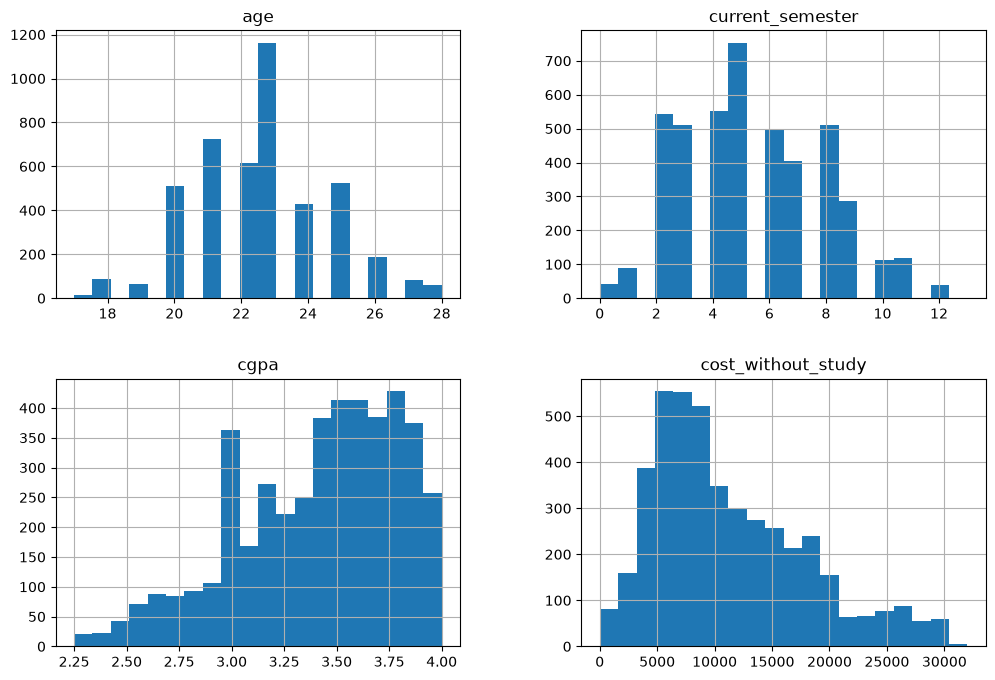

In [22]:
# Numeric features distribution
numeric_features = [
    'age',
    'current_semester',
    'cgpa',
    'cost_without_study'
]

df[numeric_features].hist(figsize=(12, 8), bins=20)

In [23]:
# Depression by numeric features
df.groupby('depression')[numeric_features].mean().T

depression,0,1
age,22.660742,22.506245
current_semester,5.429053,5.325562
cgpa,3.435271,3.351574
cost_without_study,11169.578302,11442.398834


In [24]:
df.groupby('depression')[numeric_features].median().T

depression,0,1
age,23.0,23.00
current_semester,5.0,5.00
cgpa,3.5,3.42
cost_without_study,9300.0,10000.00


### Feature Importance Analysis

In [25]:
# Extract features and target
y = df.depression
X = df.drop('depression', axis=1)

In [26]:
from sklearn.model_selection import train_test_split

# Train / Test split
df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df.depression
)

# Train / Validation split
df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=42,
    stratify=df_full_train.depression
)

# Reset indexes
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Isolate target
y_train = df_train.depression.values
y_val = df_val.depression.values
y_test = df_test.depression.values

# Remove target from feature sets
del df_train['depression']
del df_val['depression']
del df_test['depression']

In [27]:
# Check proportions
len(df_train), len(df_val), len(df_test)

(2678, 893, 893)

In [28]:
# Features Mutual Info Score

categorical = [
    'gender',
    'family_background',
    'relationship_status',
    'marital_status',
    'living_style',
    'friend_circle',
    'health_condition',
    'home_division'
]

numerical = [
    'age',
    'current_semester',
    'cgpa',
    'cost_without_study'
]

In [29]:
# For categorical variables
from sklearn.metrics import mutual_info_score

def mutual_info_depression_score(series):
    return mutual_info_score(series, y_train)

mi = df_train[categorical].apply(mutual_info_depression_score)

mi.sort_values(ascending=False)

health_condition       0.370008
relationship_status    0.041224
marital_status         0.014171
friend_circle          0.005883
family_background      0.005393
home_division          0.003860
living_style           0.000527
gender                 0.000002
dtype: float64

In [30]:
# For numerical variables
from sklearn.feature_selection import mutual_info_classif
import pandas as pd

mi_numeric = mutual_info_classif(
    df_train[numerical],
    y_train,
    discrete_features=False,
    random_state=42
)

mi_numeric = pd.Series(
    mi_numeric,
    index=numerical
)

mi_numeric.sort_values(ascending=False)

cgpa                  0.022075
current_semester      0.004584
age                   0.002727
cost_without_study    0.000900
dtype: float64

In [31]:
# All feature importance
mi_all = pd.concat([mi, mi_numeric])

mi_all = mi_all.sort_values(ascending=False)

mi_all

health_condition       0.370008
relationship_status    0.041224
cgpa                   0.022075
marital_status         0.014171
friend_circle          0.005883
family_background      0.005393
current_semester       0.004584
home_division          0.003860
age                    0.002727
cost_without_study     0.000900
living_style           0.000527
gender                 0.000002
dtype: float64

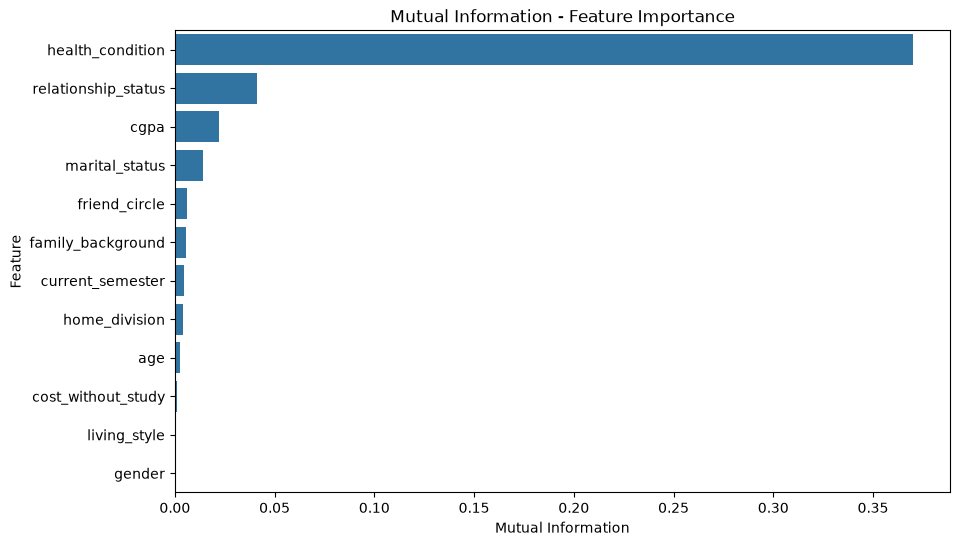

In [32]:
# Plot
plt.figure(figsize=(10, 6))

sns.barplot(
    x=mi_all.values,
    y=mi_all.index
)

plt.title('Mutual Information - Feature Importance')
plt.xlabel('Mutual Information')
plt.ylabel('Feature')

plt.show()

In [33]:
# Deep dive into health_condition to check data leakage
pd.crosstab(
    df_train.health_condition,
    y_train,
    normalize='index'
) * 100

col_0,0,1
health_condition,,
abnormal,45.557656,54.442344
critical,0.000000,100.000000
good,100.000000,0.000000
normal,95.184136,4.815864


In [34]:
# All student with "critical" have depression
# No student with "good" has depresion

In [35]:
pd.crosstab(
    df_train.health_condition,
    y_train
)

col_0,0,1
health_condition,,
abnormal,241,288
critical,0,382
good,708,0
normal,1008,51


In [36]:
# Decision: exclude the variable due to its unusually strong association with the target variable.

X = df.drop(['depression', 'health_condition'], axis=1)
y = df.depression

In [37]:
# Deep dive into relationship_status
pd.crosstab(
    df_train.relationship_status,
    y_train,
    normalize='index'
) * 100

col_0,0,1
relationship_status,,
complicated,84.920635,15.079365
in_a_relationship,89.164786,10.835214
single,63.625450,36.374550


### Baseline Model Training: Logistic Regression

In [38]:
# Update validation framework
X = df.drop(['depression', 'health_condition'], axis=1)
y = df.depression

# Train / Test split
X_full_train, X_test, y_full_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train / Validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_full_train, y_full_train,
    test_size=0.25, random_state=42, stratify=y_full_train
)

# Reset indexes
X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

y_train = y_train.reset_index(drop=True)
y_val = y_val.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

In [39]:
# Prepare categorical variables
from sklearn.feature_extraction import DictVectorizer

train_dict = X_train.to_dict(orient='records')
val_dict = X_val.to_dict(orient='records')

dv = DictVectorizer(sparse=True)

X_train_encoded = dv.fit_transform(train_dict)
X_val_encoded = dv.transform(val_dict)

In [40]:
# Train logistic regression
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=5000)

model.fit(X_train_encoded, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [41]:
# Evaluate
y_pred = model.predict_proba(X_val_encoded)[:, 1]

In [42]:
# ROC AUC
from sklearn.metrics import roc_auc_score

roc_auc_score(y_val, y_pred)

0.7302577845839714

In [43]:
# Accuracy
from sklearn.metrics import accuracy_score

accuracy_score(y_val, y_pred >= 0.5)

0.7379619260918253

### Next Model: Decision Tree

In [44]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

for depth in [2, 3, 4, 5, 6, 10, 15, None]:

    dt = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    dt.fit(X_train_encoded, y_train)

    y_pred = dt.predict_proba(X_val_encoded)[:, 1]

    auc = roc_auc_score(y_val, y_pred)

    print(f"Depth: {depth}, AUC: {auc:.3f}")

Depth: 2, AUC: 0.674
Depth: 3, AUC: 0.693
Depth: 4, AUC: 0.707
Depth: 5, AUC: 0.706
Depth: 6, AUC: 0.709
Depth: 10, AUC: 0.659
Depth: 15, AUC: 0.617
Depth: None, AUC: 0.611


In [45]:
# Best result: max_depth=6, gives AUC 0.709.

### Next Model: Random Forest

In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

for depth in [5, 10, 15, None]:
    for n in [10, 50, 100, 200]:

        rf = RandomForestClassifier(
            n_estimators=n,
            max_depth=depth,
            random_state=42,
            n_jobs=-1
        )

        rf.fit(X_train_encoded, y_train)

        y_pred = rf.predict_proba(X_val_encoded)[:, 1]

        auc = roc_auc_score(y_val, y_pred)

        print(f"Depth: {depth}, N: {n}, AUC: {auc:.3f}")

Depth: 5, N: 10, AUC: 0.728
Depth: 5, N: 50, AUC: 0.738
Depth: 5, N: 100, AUC: 0.743
Depth: 5, N: 200, AUC: 0.743
Depth: 10, N: 10, AUC: 0.756
Depth: 10, N: 50, AUC: 0.771
Depth: 10, N: 100, AUC: 0.773
Depth: 10, N: 200, AUC: 0.772
Depth: 15, N: 10, AUC: 0.735
Depth: 15, N: 50, AUC: 0.761
Depth: 15, N: 100, AUC: 0.762
Depth: 15, N: 200, AUC: 0.764
Depth: None, N: 10, AUC: 0.733
Depth: None, N: 50, AUC: 0.748
Depth: None, N: 100, AUC: 0.755
Depth: None, N: 200, AUC: 0.757


In [47]:
# Best:
RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

### Next Model: XGBoost

In [48]:
from xgboost import XGBClassifier

for depth in [3, 5, 7]:
    for learning_rate in [0.01, 0.05, 0.1]:

        xgb = XGBClassifier(
            n_estimators=100,
            max_depth=depth,
            learning_rate=learning_rate,
            random_state=42,
            eval_metric='logloss',
            n_jobs=-1
        )

        xgb.fit(X_train_encoded, y_train)

        y_pred = xgb.predict_proba(X_val_encoded)[:, 1]

        auc = roc_auc_score(y_val, y_pred)

        print(
            f"Depth: {depth}, "
            f"LR: {learning_rate}, "
            f"AUC: {auc:.3f}"
        )

Depth: 3, LR: 0.01, AUC: 0.724
Depth: 3, LR: 0.05, AUC: 0.752
Depth: 3, LR: 0.1, AUC: 0.752
Depth: 5, LR: 0.01, AUC: 0.750
Depth: 5, LR: 0.05, AUC: 0.770
Depth: 5, LR: 0.1, AUC: 0.762
Depth: 7, LR: 0.01, AUC: 0.751
Depth: 7, LR: 0.05, AUC: 0.762
Depth: 7, LR: 0.1, AUC: 0.757


In [49]:
# Best:
XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


Best Result Overall: Random Forest: 0.773

### Hyperparameters tuning for Random Forest

In [50]:
for depth in [8, 10, 12]:
    for min_samples_leaf in [1, 3, 5]:
        for max_features in [0.5, 0.8, 1.0]:

            rf = RandomForestClassifier(
                n_estimators=200,
                max_depth=depth,
                min_samples_leaf=min_samples_leaf,
                max_features=max_features,
                random_state=42,
                n_jobs=-1
            )

            rf.fit(X_train_encoded, y_train)

            y_pred = rf.predict_proba(X_val_encoded)[:, 1]

            auc = roc_auc_score(y_val, y_pred)

            print(
                f"Depth: {depth}, "
                f"Leaf: {min_samples_leaf}, "
                f"Features: {max_features}, "
                f"AUC: {auc:.3f}"
            )

Depth: 8, Leaf: 1, Features: 0.5, AUC: 0.763
Depth: 8, Leaf: 1, Features: 0.8, AUC: 0.763
Depth: 8, Leaf: 1, Features: 1.0, AUC: 0.760
Depth: 8, Leaf: 3, Features: 0.5, AUC: 0.767
Depth: 8, Leaf: 3, Features: 0.8, AUC: 0.762
Depth: 8, Leaf: 3, Features: 1.0, AUC: 0.764
Depth: 8, Leaf: 5, Features: 0.5, AUC: 0.766
Depth: 8, Leaf: 5, Features: 0.8, AUC: 0.767
Depth: 8, Leaf: 5, Features: 1.0, AUC: 0.763
Depth: 10, Leaf: 1, Features: 0.5, AUC: 0.763
Depth: 10, Leaf: 1, Features: 0.8, AUC: 0.765
Depth: 10, Leaf: 1, Features: 1.0, AUC: 0.763
Depth: 10, Leaf: 3, Features: 0.5, AUC: 0.773
Depth: 10, Leaf: 3, Features: 0.8, AUC: 0.766
Depth: 10, Leaf: 3, Features: 1.0, AUC: 0.767
Depth: 10, Leaf: 5, Features: 0.5, AUC: 0.770
Depth: 10, Leaf: 5, Features: 0.8, AUC: 0.767
Depth: 10, Leaf: 5, Features: 1.0, AUC: 0.766
Depth: 12, Leaf: 1, Features: 0.5, AUC: 0.767
Depth: 12, Leaf: 1, Features: 0.8, AUC: 0.764
Depth: 12, Leaf: 1, Features: 1.0, AUC: 0.762
Depth: 12, Leaf: 3, Features: 0.5, AUC: 0.7

Best parameters:
n_estimators: 200
max_depth: 10
min_samples_leaf: 3
max_features: 0.5

Gives Validation ROC AUC: 0.773

### Evaluate the model with other metrics

In [51]:
best_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=3,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train_encoded, y_train)

y_pred = best_rf.predict_proba(X_val_encoded)[:, 1]
y_pred_binary = (y_pred >= 0.5).astype(int)

In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print('Accuracy:', accuracy_score(y_val, y_pred_binary))
print('Precision:', precision_score(y_val, y_pred_binary))
print('Recall:', recall_score(y_val, y_pred_binary))
print('F1:', f1_score(y_val, y_pred_binary))
print('ROC AUC:', roc_auc_score(y_val, y_pred))

print(confusion_matrix(y_val, y_pred_binary))

Accuracy: 0.7670772676371781
Precision: 0.6379310344827587
Recall: 0.30833333333333335
F1: 0.4157303370786517
ROC AUC: 0.7727794793261868
[[611  42]
 [166  74]]


In [53]:
# Adjust the threshold due to low recall
y_pred_binary = (y_pred >= 0.5).astype(int)

In [54]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:

    y_pred_binary = (y_pred >= threshold).astype(int)

    precision = precision_score(y_val, y_pred_binary)
    recall = recall_score(y_val, y_pred_binary)
    f1 = f1_score(y_val, y_pred_binary)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.1 | Precision: 0.327 | Recall: 0.967 | F1: 0.489
Threshold: 0.2 | Precision: 0.370 | Recall: 0.871 | F1: 0.519
Threshold: 0.3 | Precision: 0.458 | Recall: 0.721 | F1: 0.560
Threshold: 0.4 | Precision: 0.539 | Recall: 0.542 | F1: 0.541
Threshold: 0.5 | Precision: 0.638 | Recall: 0.308 | F1: 0.416
Threshold: 0.6 | Precision: 0.674 | Recall: 0.129 | F1: 0.217


In [ ]:
# I will use 0.3

### Evalute the model using test part

In [56]:
test_dict = X_test.to_dict(orient='records')
X_test_encoded = dv.transform(test_dict)

In [57]:
X_final_train = pd.concat([X_train, X_val])
y_final_train = pd.concat([y_train, y_val])

final_dict = X_final_train.to_dict(orient='records')

dv_final = DictVectorizer(sparse=True)

X_final_encoded = dv_final.fit_transform(final_dict)

best_rf.fit(X_final_encoded, y_final_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total numb

In [58]:
y_test_proba = best_rf.predict_proba(X_test_encoded)[:, 1]

y_test_pred = (y_test_proba >= 0.3).astype(int)

In [59]:
print('ROC AUC:', roc_auc_score(y_test, y_test_proba))
print('Accuracy:', accuracy_score(y_test, y_test_pred))
print('Precision:', precision_score(y_test, y_test_pred))
print('Recall:', recall_score(y_test, y_test_pred))
print('F1:', f1_score(y_test, y_test_pred))

print(confusion_matrix(y_test, y_test_pred))

ROC AUC: 0.7268504338948444
Accuracy: 0.6674132138857782
Precision: 0.42318059299191374
Recall: 0.6541666666666667
F1: 0.513911620294599
[[439 214]
 [ 83 157]]
